# Desafío

En esta sesión trabajaremos con una serie de base de datos sobre letras musicales de distintos artistas. Cada uno de los ​csv se encuentra en la carpeta ​dump dentro del proyecto. Cada csv tiene el nombre del artista a analizar. Los archivos contienen el nombre del artista, el género musical del artista, el nombre de la canción y las letras. En base a esta información, se les pide un modelo generativo que pueda predecir el género de una canción a partir de la letra de una canción. Existen 4 géneros que se registran en la base de datos, por lo que para esta actividad trabajaremos con un Multinomial Naive Bayes.

## Parte 1: Preparar el ambiente de trabajo

- Importe los módulos `​numpy​`, `​pandas​`, `​matplotlib​`, `​seaborn​`, `​glob` y `os` siguiendo las buenas prácticas. Los últimos dos módulos permitirán realizar la importación de múltiples archivos dentro de la carpeta dump.
- Para ello genere un objeto que guarde en una lista todos los archivos alojados en ​dump utilizando `​glob.glob` y ​`os.getcwd()` para extraer las rutas absolutas. Posteriormente genere un objeto `​pd.DataFrame`​ que contenga todos los `​csv​`.
- Asegúrese de eliminar la columna `Unnamed: 0` que se genera por defecto.

## Parte 2: Descripción de los datos

- Utilizando el objeto creado en el Ejercicio 1, genere dos gráficos de barras que resuman la siguiente información:
    + La cantidad de canciones registradas por cada artista, ordenados de mayor a menor.
    + La cantidad de canciones registradas en cada género, ordenados de mayor a menor.
- Comente sobre las principales tendencias.

## Parte 3: Matriz de ocurrencias

**Tokenización de Textos**
Para poder trabajar con textos, debemos pasarlos a una **​matriz dispersa**​, donde cada fila representará una entrada (en este caso, una canción), y cada columna **​representará una palabra (token)**​. Este es el proceso de tokenización: Identificar la ocurrencia de una palabra específica dentro de un conjunto de textos (corpus). El tokenizador más simple `​sklearn.feature_extraction.text.CountVectorizer` genera una colección de textos a una matriz que representa la frecuencia **​dentro del texto** de una palabra específica.

El tokenizador funciona de la siguiente manera:

```python	
from​ sklearn.feature_extraction.text ​import​ CountVectorizer
# instanciamos un objeto
count_vectorizer=CountVectorizer(stop_words=​'english'​)
# Implementamos los pasos fit y transform
count_vectorizer_fit = count_vectorizer.fit_transform(lista_de_textos)
# Extraemos tokens (palabras)
words = count_vectorizer.get_feature_names()
# extraemos frecuencia
words_freq = count_vectorizer_fit.toarray().sum(axis=​0​)
```
- Importe la clase `​CountVectorizer` dentro de los módulos `​feature_extraction.text` de la librería `​sklearn​`. Lea la documentación asociada a ésta. ¿Cuál es el objetivo de esta clase?
- Aplique la clase para extraer las 100 palabras más repetidas en toda la base de datos.
- Genere una función que replique el procedimiento para cada uno de los géneros.
- Comente sobre las principales características de cada género en cuanto a sus palabras

## Parte 4: Entrenamiento del Modelo

**`​sklearn​` Pipelines**

La clase `​Pipeline` del módulo `​sklearn.pipeline` permite concatenar múltiples pasos de procesamiento y preprocesamiento en un estimador generado por algún método de `scikit-learn`​. En sí, la clase cuenta con los métodos clásicos `​fit​`, `​predict`, `​score` y presenta un comportamiento idéntico a los demás objetos de `​scikit-learn`​. Uno de los usos más comunes es para concatenar pasos de preprocesamiento con un modelo.

**Componentes de un `​Pipeline`**

Imaginemos que deseamos implementar el siguiente modelo. Considerando un conjunto de datos, deseo **​Estandarizar​**, posteriormente **​extraer sus principales componentes** y finalmente aplicar un modelo de **​regresión lineal**​. Este flujo se puede reexpresar como:

```python
pipeline_model = Pipeline([(​'scale'​, StandardScaler()),
                (​'pca'​, RandomizedPCA(n_components=​3​)),
                (​'model'​, LinearRegression())])
```

Algunos de los elementos a considerar:

1. Cada paso se considera como una tupla, donde se declara el nombre del paso y la función a implementar. En este caso, nuestro primer paso es estandarizar la matriz, por lo que asociamos el método `​StandardScaler​` con el string `​scale​`.
2. Todos los pasos declarados se incorporan en una lista, donde el orden de ingreso representa el orden de ejecución.

Posteriormente el objeto creado puede utilizarse con los siguientes métodos
```python
pipeline_model.fit(X_train, y_train)
y_hat = pipeline_model.predict(y_test)
```

- Importe `​MultinomialNB`​, `​train_test_split​`, `​Pipeline​`, `​confusion_matrix` y `classification_report​`.
- Genere las muestras de entrenamiento y validación reservando un 40% para validación y declarando una semilla pseudoaleatoria.
- Monte el modelo dentro de un `​Pipeline​`, donde el primer paso es implementar `CountVectorizer​` y el segundo es ejecutar el clasificador `​MultinomialNB​`.
- A continuación se les presenta una lista de letras, ¿cuáles serían las predicciones correspondientes?

```python
[​
"I got a place in the underworld"​, ​# Brody Dalle - Underworld
"As veils of ignorance, hatred retains Storm of arrows through karma Seeking light through samsara"​, ​# Gorguts - Forgotten Arrows
"Bye bye Don't want to be a fool for you Just another player in your game for two You may hate me but it ain't no lie"​, ​# N'SYNC - Bye Bye Bye
"Move bitch, get out the way Get out the way bitch, get out the way Move bitch, get out the way Get out the way bitch, get out the way"​, ​# Ludacris - Move B*tch
"Sexual violence doesn'​t start ​and​ end ​with​ rape It starts ​in​ our books ​and behind our school gates​" # IDLES - Mother,
"Take it from the girl you claimed to\ love You gonna get some bad karma I'​m the one who had to learn to build a heart made of armor From the girl who made you soup ​and​ tied your shoes when you were hurting\ You are ​not​ deserving, you are ​not​ deserving​" #Banks - Drowning
]
``` 
- Genere una predicción implementando la muestra de validación y contraste las predicciones del modelo con las etiquetas verdaderas. Reporte las principales métricas.
  
## Parte 5: Mejora del Modelo

- Proponga una estrategia para mejorar el desempeño del modelo en la categoría con peores métricas.
- Repita los pasos de entrenamiento y reporte de métricas, esta vez incluyendo los nuevos datos suministrados.
- Comente sobre el desempeño general de este.

# Importación de librerias

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Importación de la base de datos y preparación:

In [14]:
#Configuración de estilo para los gráficos
sns.set_theme(style="whitegrid")

#Ruta de la carpeta dump
path = os.path.join(os.getcwd(), 'dump', '*.csv')

#glob.glob obtiene todas las rutas absolutas de los archivos
archivos_csv = glob.glob(path)

#Generamos un DataFrame que contenga todos los csv concatenados
lista_df = [pd.read_csv(archivo) for archivo in archivos_csv]
df_letras = pd.concat(lista_df, ignore_index=True)

#Eliminamos la columna 'Unnamed: 0'
if 'Unnamed: 0' in df_letras.columns:
    df_letras = df_letras.drop(columns=['Unnamed: 0'])

#Renombramos las columnas a los nombres reales:
df_letras = df_letras.rename(columns={
    '0': 'Artist', 
    '1': 'Genre', 
    '2': 'Song', 
    '3': 'Lyrics'
})

print(df_letras.head())

    Artist  Genre                 Song  \
0  Anthrax  metal           Deathrider   
1  Anthrax  metal  Metal Thrashing Mad   
2  Anthrax  metal         I'm Eighteen   
3  Anthrax  metal                Panic   
4  Anthrax  metal           Subjugator   

                                              Lyrics  
0  Riding hard, high in the saddle \n Winged stee...  
1  Racing down the road \n In a street machine of...  
2  Lines form on my face and hands \n Lines form ...  
3  Move it to the front \n Reaching for the light...  
4  Out in the streets \n We're fighting tonight \...  


# Descripción de los datos:

C:\Users\lukas\AppData\Local\Temp\ipykernel_3060\1791199486.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Artist', data=df_letras, order=df_letras['Artist'].value_counts().index, palette='viridis')


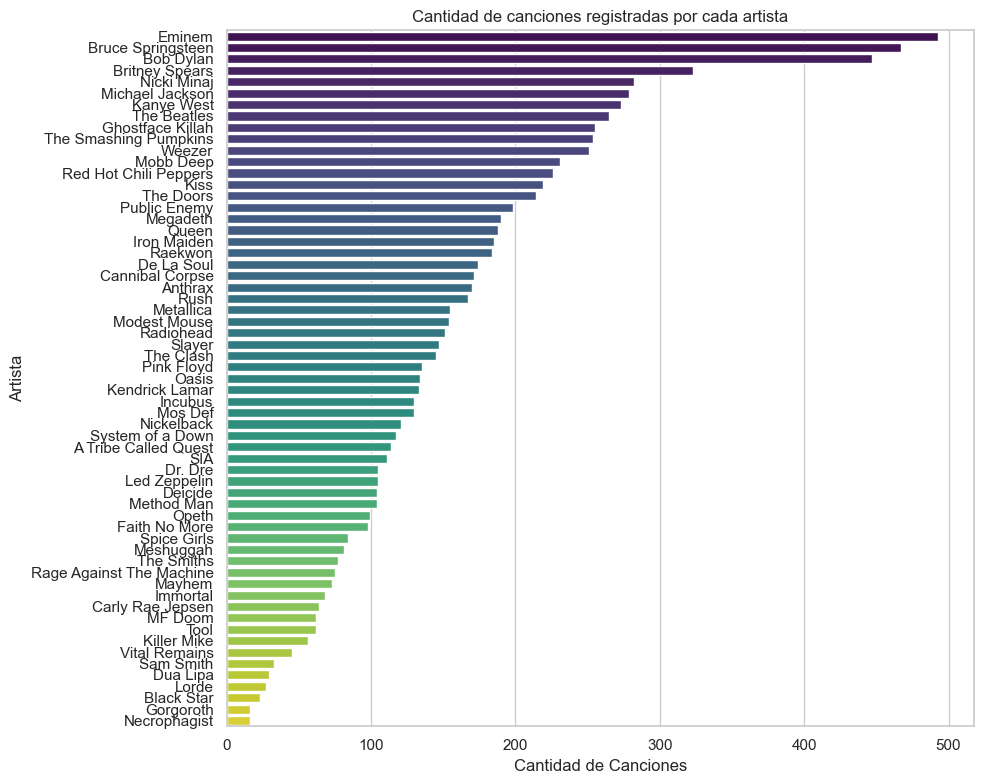

C:\Users\lukas\AppData\Local\Temp\ipykernel_3060\1791199486.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Genre', data=df_letras, order=df_letras['Genre'].value_counts().index, palette='magma')


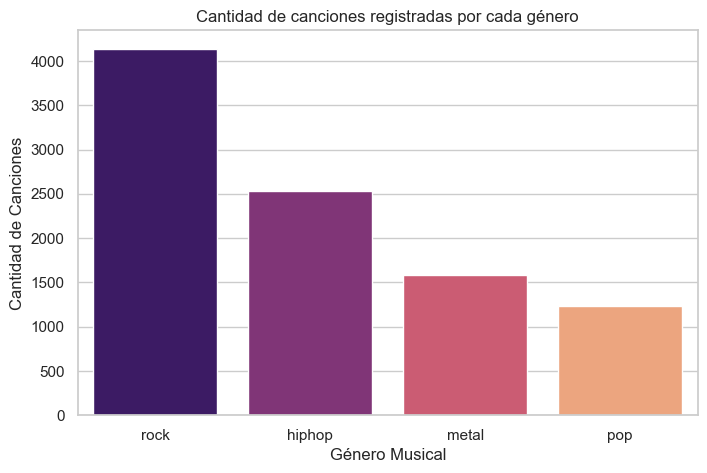

In [6]:
#Cantidad de canciones registradas por cada artista
plt.figure(figsize=(10, 8))
#Ordenamos de mayor a menor utilizando value_counts().index
sns.countplot(y='Artist', data=df_letras, order=df_letras['Artist'].value_counts().index, palette='viridis')
plt.title('Cantidad de canciones registradas por cada artista')
plt.xlabel('Cantidad de Canciones')
plt.ylabel('Artista')
plt.tight_layout()
plt.show()

#Cantidad de canciones registradas en cada género
plt.figure(figsize=(8, 5))
sns.countplot(x='Genre', data=df_letras, order=df_letras['Genre'].value_counts().index, palette='magma')
plt.title('Cantidad de canciones registradas por cada género')
plt.xlabel('Género Musical')
plt.ylabel('Cantidad de Canciones')
plt.show()

# Matriz de ocurrencias:

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

#Eliminamos posibles valores nulos en las letras
df_letras = df_letras.dropna(subset=['Lyrics'])

#Instanciar el objeto
count_vectorizer = CountVectorizer(stop_words='english')

#Ajustes
count_vectorizer_fit = count_vectorizer.fit_transform(df_letras['Lyrics'])

#Extraer tokens y frecuencias
words = count_vectorizer.get_feature_names_out() # En versiones nuevas de sklearn es get_feature_names_out()
words_freq = count_vectorizer_fit.toarray().sum(axis=0)

#Creamos DataFrame con las palabras y frecuencias, y extraemos las 100 más repetidas
df_words = pd.DataFrame({'Palabra': words, 'Frecuencia': words_freq})
top_100_general = df_words.sort_values(by='Frecuencia', ascending=False).head(100)
print("TOP 100 PALABRAS EN GENERAL:\n", top_100_general)

#Función para replicar el procedimiento por cada género
def top_words_by_genre(df, genre, top_n=100):
    df_subset = df[df['Genre'] == genre]
    
    cv = CountVectorizer(stop_words='english')
    cv_fit = cv.fit_transform(df_subset['Lyrics'])
    
    words = cv.get_feature_names_out()
    freq = cv_fit.toarray().sum(axis=0)
    
    df_freq = pd.DataFrame({'Palabra': words, 'Frecuencia': freq})
    return df_freq.sort_values(by='Frecuencia', ascending=False).head(top_n)

#Iterar sobre cada género para obtener sus top 100 palabras
generos = df_letras['Genre'].unique()
for g in generos:
    print(f"\nTop 10 palabras del género: {g}")
    print(top_words_by_genre(df_letras, g, top_n=10).to_string(index=False))



TOP 100 PALABRAS EN GENERAL:
       Palabra  Frecuencia
24950    like       19629
12859     don       17398
23856    know       14962
18439     got       14171
23287    just       13978
...       ...         ...
11041   death        1897
24615    left        1895
43442   thing        1882
14305     end        1829
41068    stay        1828

[100 rows x 2 columns]

Top 10 palabras del género: metal
Palabra  Frecuencia
   life        1233
    don        1181
  death        1139
   time        1096
     ll        1069
   know        1048
   just         993
  blood         884
   like         869
    die         866

Top 10 palabras del género: hiphop
Palabra  Frecuencia
   like       12055
    got        7613
    don        7604
   know        6535
   just        6272
   shit        5546
    ain        4782
  cause        4737
    man        4481
     yo        4425

Top 10 palabras del género: rock
Palabra  Frecuencia
    don        5284
   love        5114
   know        4702
     oh  

# Entrenamiento del modelo:

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report

#Variables independientes (X) y dependientes (y)
X = df_letras['Lyrics']
y = df_letras['Genre']

#División de la muestra (40% de prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

#Creación del Pipeline
pipeline_model = Pipeline([
    ('vectorizer', CountVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

#Entrenar el modelo
pipeline_model.fit(X_train, y_train)

#Predicciones:
nuevas_letras = [
    "I got a place in the underworld", # Brody Dalle
    "As veils of ignorance, hatred retains Storm of arrows through karma Seeking light through samsara", # Gorguts
    "Bye bye Don't want to be a fool for you Just another player in your game for two You may hate me but it ain't no lie", # N'SYNC
    "Move bitch, get out the way Get out the way bitch, get out the way Move bitch, get out the way Get out the way bitch, get out the way", # Ludacris
    "Sexual violence doesn't start and end with rape It starts in our books and behind our school gates", # IDLES
    "Take it from the girl you claimed to love You gonna get some bad karma I'm the one who had to learn to build a heart made of armor From the girl who made you soup and tied your shoes when you were hurting You are not deserving, you are not deserving" # Banks
]

predicciones_nuevas = pipeline_model.predict(nuevas_letras)
print("\nPredicciones para las nuevas canciones:")
for letra, pred in zip(nuevas_letras, predicciones_nuevas):
    print(f"Predicción: {pred} | Letra: {letra[:30]}...")

#Predicción y métricas:
y_pred = pipeline_model.predict(X_test)

print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))


Predicciones para las nuevas canciones:
Predicción: rock | Letra: I got a place in the underworl...
Predicción: metal | Letra: As veils of ignorance, hatred ...
Predicción: rock | Letra: Bye bye Don't want to be a foo...
Predicción: pop | Letra: Move bitch, get out the way Ge...
Predicción: metal | Letra: Sexual violence doesn't start ...
Predicción: rock | Letra: Take it from the girl you clai...

Matriz de Confusión:
[[ 929    3   17   49]
 [  23  449    5  175]
 [  54    7  183  207]
 [  90   69   81 1455]]

Reporte de Clasificación:
              precision    recall  f1-score   support

      hiphop       0.85      0.93      0.89       998
       metal       0.85      0.69      0.76       652
         pop       0.64      0.41      0.50       451
        rock       0.77      0.86      0.81      1695

    accuracy                           0.79      3796
   macro avg       0.78      0.72      0.74      3796
weighted avg       0.79      0.79      0.79      3796



# Mejora del modelo:

Los géneros con peores métricas son aquellos con la menor cantidad de canciones en el DataFrame original. Las estrategias son:

Recolección de más datos: Integrar más registros a los géneros menos representados.

Utilizar TfidfVectorizer en vez de CountVectorizer: Reduce el peso de las palabras frecuentes que aparecen en todos los géneros e incrementa la importancia de palabras exclusivas de un género específico.

A continuación, implementamos la mejora utilizando TfidfVectorizer:

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

#Generamos un nuevo pipeline con mejoras
pipeline_mejorado = Pipeline([
    ('vectorizer', TfidfVectorizer(stop_words='english', ngram_range=(1, 2))),
    ('classifier', MultinomialNB(alpha=0.1)) 
])

#Entrenamos el nuevo modelo
pipeline_mejorado.fit(X_train, y_train)

#Predecir sobre test
y_pred_mejorado = pipeline_mejorado.predict(X_test)

#Reporte de las métricas:
print("\nReporte de Clasificación Modelo Mejorado:")
print(classification_report(y_test, y_pred_mejorado))


Reporte de Clasificación Modelo Mejorado:
              precision    recall  f1-score   support

      hiphop       0.82      0.94      0.88       998
       metal       0.99      0.44      0.61       652
         pop       0.97      0.13      0.23       451
        rock       0.70      0.95      0.80      1695

    accuracy                           0.76      3796
   macro avg       0.87      0.61      0.63      3796
weighted avg       0.81      0.76      0.72      3796

